<a href="https://colab.research.google.com/github/sara-iqbal/Children-s-Social-Care-Data-Pipeline/blob/main/childrens_social_care_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Children's Social Care Data Pipeline
### Synthetic case data → data quality checks → SSDA903-style statutory return → performance scorecard

**Author:** Sara Iqbal
**Tools:** Python (pandas, NumPy, Matplotlib), SQL (SQLite), Power BI
**Data:** 100% synthetic. Every child, worker and record in this notebook is generated by code. No real person is represented.

## Why this project exists

Children's services teams in England record their work in case management systems such as Liquidlogic. Behind the scenes, an intelligence and performance team turns those records into three things:

1. **Clean data**: checking that records are complete and logically consistent, and sending errors back to practitioners to fix.
2. **Statutory returns**: annual submissions to the Department for Education, such as the **SSDA903** return for children looked after.
3. **Performance information**: monthly scorecards that help managers see whether children are being seen, assessed and supported on time.

Real child-level data is, rightly, never public. So this notebook builds a realistic **synthetic** version of a case management extract for two fictional borough services (Kingston and Richmond), plants realistic recording errors in it, and then runs the full analyst workflow end to end.

## How the notebook is organised

| Section | What happens |
|---|---|
| 1. Setup | Libraries, settings and the reporting year |
| 2. Generate synthetic data | Children, referrals, assessments, child protection plans, care episodes and care leavers |
| 3. Load into SQL | The tables go into a SQLite database and are queried the way you would query a reporting warehouse |
| 4. Data quality validation | Ten rules, an exceptions report, and a breakdown by team and worker |
| 5. SSDA903-style return | Header, Episodes and OC3 (care leaver) tables built to the DfE layout |
| 6. Performance scorecard | Eight standard KPIs with targets and red/amber/green (RAG) ratings |
| 7. Trends and breakdowns | Monthly trends and service mix |
| 8. Export | CSVs for Power BI and a JSON file for the web dashboard |
| 9. Summary | What the numbers say |

> Run the cells from top to bottom (**Runtime → Run all** in Colab). The random seed is fixed, so you will get the same numbers every time.

## 1. Setup

Everything used here is already installed in Google Colab, so there is nothing to `pip install`.

In [ ]:
# Core libraries
import numpy as np
import pandas as pd
import sqlite3
import json
from pathlib import Path

# Charts
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Make tables easier to read in the notebook
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# A fixed seed means the "random" data is identical every time the notebook runs
SEED = 42
rng = np.random.default_rng(SEED)

# Folders for everything we export
OUT = Path("outputs")
for sub in ["powerbi", "ssda903", "dashboard", "charts"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

print("Setup complete. Outputs will be saved to the folder:", OUT)

Setup complete. Outputs will be saved to the folder: outputs


### Reporting year and settings

Statutory returns run from **1 April to 31 March**. We report on **2025-26** and generate two earlier years of history so that measures such as "re-referred within 12 months" have past data to look back on.

The population figures are **illustrative round numbers**, used only to turn counts into rates per 10,000 children.

In [ ]:
DATA_START  = pd.Timestamp("2023-04-01")   # start of generated history
YEAR_START  = pd.Timestamp("2025-04-01")   # reporting year start
YEAR_END    = pd.Timestamp("2026-03-31")   # reporting year end (the "snapshot" date)

BOROUGHS = ["Kingston", "Richmond"]
POP_UNDER_18 = {"Kingston": 40_000, "Richmond": 45_000}   # illustrative only

# Bank holidays in England, needed to count WORKING days correctly
BANK_HOLIDAYS = pd.to_datetime([
    "2023-01-02","2023-04-07","2023-04-10","2023-05-01","2023-05-08","2023-05-29","2023-08-28","2023-12-25","2023-12-26",
    "2024-01-01","2024-03-29","2024-04-01","2024-05-06","2024-05-27","2024-08-26","2024-12-25","2024-12-26",
    "2025-01-01","2025-04-18","2025-04-21","2025-05-05","2025-05-26","2025-08-25","2025-12-25","2025-12-26",
    "2026-01-01","2026-04-03","2026-04-06","2026-05-04","2026-05-25","2026-08-31","2026-12-25","2026-12-28",
]).values.astype("datetime64[D]")

def working_days_between(start, end):
    '''Working days from start to end (weekends and bank holidays excluded).
    Returns NaN where either date is missing.'''
    s = pd.to_datetime(start); e = pd.to_datetime(end)
    mask = s.notna() & e.notna()
    out = pd.Series(np.nan, index=s.index)
    out[mask] = np.busday_count(s[mask].values.astype("datetime64[D]"),
                                e[mask].values.astype("datetime64[D]"),
                                holidays=BANK_HOLIDAYS)
    return out

def add_working_days(start, n_days):
    '''Move a date forward by n working days.'''
    return pd.to_datetime(np.busday_offset(pd.to_datetime(start).values.astype("datetime64[D]"),
                                           n_days, roll="forward", holidays=BANK_HOLIDAYS))

def random_dates(start, end, n):
    '''n random dates, uniformly spread between start and end.'''
    span = (end - start).days
    return start + pd.to_timedelta(rng.integers(0, span + 1, n), unit="D")

def age_on(dob, on_date):
    '''Age in whole years on a given date.'''
    dob = pd.to_datetime(pd.Series(dob))
    # on_date can be one date (e.g. 31 March) or a column of dates
    if isinstance(on_date, pd.Series):
        on = pd.to_datetime(on_date)
        oy, om, od = on.dt.year, on.dt.month, on.dt.day
    else:
        on = pd.Timestamp(on_date)
        oy, om, od = on.year, on.month, on.day
    years = oy - dob.dt.year
    had_birthday = (om > dob.dt.month) | ((om == dob.dt.month) & (od >= dob.dt.day))
    return years - (~had_birthday).astype(int)

print(f"Reporting year: {YEAR_START.date()} to {YEAR_END.date()}")

Reporting year: 2025-04-01 to 2026-03-31


## 2. Generate the synthetic case data

The data mirrors the way a child moves through children's social care:

**Referral** → **Assessment** → (sometimes) **Child Protection plan** → (sometimes) **Children Looked After (in care)** → **Care leaver**

Every table links back to a `child_id`. The generator also builds in some realistic behaviour, so the analysis has something to find:

* One assessment team is under pressure, so its assessments take longer.
* Timeliness dips for assessments started in the summer holidays and in December, when staff take leave.
* A small number of children move placement many times.
* About 2–5% of records contain the kinds of recording errors analysts really see.

### 2.1 Teams and social workers

In [ ]:
teams = []
for b in BOROUGHS:
    for t in ["Assessment Team A", "Assessment Team B"]:
        teams.append({"borough": b, "team": f"{b} {t}"})
teams = pd.DataFrame(teams)

# 8 social workers per assessment team
workers = []
wid = 1
for _, row in teams.iterrows():
    for _ in range(8):
        workers.append({"worker_id": f"SW{wid:03d}", "team": row["team"], "borough": row["borough"]})
        wid += 1
workers = pd.DataFrame(workers)

# Built-in story: Kingston Team B is stretched (lower chance of finishing an assessment within 45 days)
TEAM_ON_TIME = {
    "Kingston Assessment Team A": 0.90,
    "Kingston Assessment Team B": 0.71,
    "Richmond Assessment Team A": 0.89,
    "Richmond Assessment Team B": 0.86,
}
workers.head()

,worker_id,team,borough
0,SW001,Kingston Assessment Team A,Kingston
1,SW002,Kingston Assessment Team A,Kingston
2,SW003,Kingston Assessment Team A,Kingston
3,SW004,Kingston Assessment Team A,Kingston
4,SW005,Kingston Assessment Team A,Kingston


### 2.2 Children

Each child gets a date of birth, sex, ethnicity (using DfE ethnicity codes), a Unique Pupil Number (UPN) and a borough. No names are needed. Real returns identify children by ID, not name.

In [ ]:
N_CHILDREN = 5200

ETHNIC_CODES = ["WBRI","WIRI","WOTH","WROM","MWBC","MWBA","MWAS","MOTH",
                "AIND","APKN","ABAN","AOTH","BCRB","BAFR","BOTH","CHNE","OOTH","REFU"]
ETHNIC_W     = [0.52,0.01,0.10,0.005,0.03,0.015,0.03,0.03,
                0.03,0.035,0.01,0.04,0.015,0.035,0.01,0.01,0.03,0.025]
ETHNIC_W     = np.array(ETHNIC_W) / np.sum(ETHNIC_W)

first_contact = random_dates(DATA_START, YEAR_END, N_CHILDREN)
# Ages at first contact: children's social care sees all ages, slightly more teenagers
AGE_W = np.array([8,6,6,6,6,6,6,6,6,6,6,6,7,7,7,6,5,3], dtype=float)
age_at_contact = rng.choice(np.arange(0, 18), N_CHILDREN, p=AGE_W / AGE_W.sum())
dob = first_contact - pd.to_timedelta(age_at_contact * 365.25 + rng.integers(0, 365, N_CHILDREN), unit="D")

children = pd.DataFrame({
    "child_id":   [f"C{100000 + i}" for i in range(N_CHILDREN)],
    "borough":    rng.choice(BOROUGHS, N_CHILDREN, p=[0.47, 0.53]),
    "sex":        rng.choice([1, 2], N_CHILDREN),          # DfE coding: 1 = male, 2 = female
    "dob":        dob.normalize(),
    "ethnicity":  rng.choice(ETHNIC_CODES, N_CHILDREN, p=ETHNIC_W),
    "disability": rng.choice(["Yes", "No"], N_CHILDREN, p=[0.08, 0.92]),
})
# UPNs: one letter + 12 digits
children["upn"] = ["A" + "".join(map(str, rng.integers(0, 10, 12))) for _ in range(N_CHILDREN)]
first_contact_lookup = dict(zip(children["child_id"], first_contact))

print(f"{len(children):,} children generated")
children.head()

5,200 children generated


,child_id,borough,sex,dob,ethnicity,disability,upn
0,C100000,Richmond,1,2015-07-19,ABAN,No,A206715516286
1,C100001,Kingston,1,2014-05-17,WBRI,No,A151724685026
2,C100002,Richmond,2,2017-07-27,WBRI,Yes,A033399888130
3,C100003,Richmond,1,2010-10-05,WBRI,No,A780119720450
4,C100004,Kingston,2,2023-09-01,WBRI,No,A459114397236


### 2.3 Referrals

Around one in five children are referred again later, which makes the **re-referral rate** a meaningful measure. The referral source mix (police, schools, health and so on) is roughly what you would see in a London borough.

In [ ]:
SOURCES   = ["Police", "Schools", "Health services", "LA services", "Individual", "Anonymous", "Other"]
SOURCE_W  = [0.27, 0.21, 0.15, 0.10, 0.08, 0.04, 0.15]

ref_rows = []
for cid, d0 in first_contact_lookup.items():
    dates = [d0]
    if rng.random() < 0.30:                          # re-referred
        dates.append(d0 + pd.Timedelta(days=int(rng.integers(30, 540))))
        if rng.random() < 0.25:
            dates.append(dates[-1] + pd.Timedelta(days=int(rng.integers(30, 500))))
    for d in dates:
        if d <= YEAR_END:
            ref_rows.append({"child_id": cid, "referral_date": d})

referrals = pd.DataFrame(ref_rows).sort_values("referral_date").reset_index(drop=True)
referrals.insert(0, "referral_id", [f"R{200000 + i}" for i in range(len(referrals))])
referrals["source"]  = rng.choice(SOURCES, len(referrals), p=SOURCE_W)
referrals["outcome"] = rng.choice(["Assessment", "No further action"], len(referrals), p=[0.76, 0.24])
referrals = referrals.merge(children[["child_id", "borough"]], on="child_id")
referrals["team"] = referrals["borough"] + " Assessment Team " + rng.choice(["A", "B"], len(referrals))

print(f"{len(referrals):,} referrals generated")
referrals.head()

6,494 referrals generated


,referral_id,child_id,referral_date,source,outcome,borough,team
0,R200000,C103673,2023-04-01,LA services,Assessment,Richmond,Richmond Assessment Team A
1,R200001,C102315,2023-04-01,Health services,Assessment,Kingston,Kingston Assessment Team A
2,R200002,C105082,2023-04-01,Health services,No further action,Richmond,Richmond Assessment Team A
3,R200003,C101408,2023-04-02,LA services,Assessment,Kingston,Kingston Assessment Team B
4,R200004,C101948,2023-04-02,LA services,Assessment,Richmond,Richmond Assessment Team A


### 2.4 Assessments

When a referral needs one, a social worker completes a **single assessment**. National guidance (*Working Together to Safeguard Children*) sets a maximum of **45 working days**.

Here's how the generator decides each assessment's length:
1. Start from the team's usual chance of finishing on time.
2. Lower that chance for assessments starting in July, August or December (staff leave).
3. Draw a duration in working days, inside or beyond the 45-day limit.

Assessments that would finish after 31 March 2026 are left **open**, with no end date, just as they would be on the real snapshot date.

In [ ]:
asmt = referrals[referrals["outcome"] == "Assessment"].copy().reset_index(drop=True)
asmt["assessment_id"] = [f"A{300000 + i}" for i in range(len(asmt))]
asmt["start_date"] = asmt["referral_date"] + pd.to_timedelta(rng.integers(0, 4, len(asmt)), unit="D")

# Allocate a worker from the referral's team
team_workers = workers.groupby("team")["worker_id"].apply(list).to_dict()
asmt["worker_id"] = [rng.choice(team_workers[t]) for t in asmt["team"]]

# Probability of finishing on time = team baseline, minus a holiday-season dip
p_on_time = asmt["team"].map(TEAM_ON_TIME) - np.where(asmt["start_date"].dt.month.isin([7, 8, 12]), 0.08, 0)
on_time = rng.random(len(asmt)) < p_on_time
wd = np.where(on_time, rng.integers(8, 46, len(asmt)), rng.integers(46, 95, len(asmt)))
asmt["end_date"] = add_working_days(asmt["start_date"], wd)

# Anything finishing after the snapshot date is still open
asmt.loc[asmt["end_date"] > YEAR_END, "end_date"] = pd.NaT

asmt["assessment_outcome"] = np.where(
    asmt["end_date"].isna(), "Open",
    rng.choice(["No further action", "Child in Need plan", "Child Protection (S47)"], len(asmt), p=[0.45, 0.42, 0.13]))

assessments = asmt[["assessment_id", "referral_id", "child_id", "borough", "team", "worker_id",
                    "start_date", "end_date", "assessment_outcome"]].copy()
print(f"{len(assessments):,} assessments generated ({assessments['end_date'].isna().sum()} still open on 31 March)")
assessments.head()

4,900 assessments generated (257 still open on 31 March)


,assessment_id,referral_id,child_id,borough,team,worker_id,start_date,end_date,assessment_outcome
0,A300000,R200000,C103673,Richmond,Richmond Assessment Team A,SW022,2023-04-01,2023-04-18,No further action
1,A300001,R200001,C102315,Kingston,Kingston Assessment Team A,SW001,2023-04-03,2023-04-18,Child in Need plan
2,A300002,R200003,C101408,Kingston,Kingston Assessment Team B,SW010,2023-04-05,2023-06-01,Child in Need plan
3,A300003,R200004,C101948,Richmond,Richmond Assessment Team A,SW022,2023-04-05,2023-04-25,Child in Need plan
4,A300004,R200006,C102441,Kingston,Kingston Assessment Team B,SW010,2023-04-02,2023-06-09,No further action


### 2.5 Child Protection plans

Assessments that conclude with a Section 47 enquiry can lead to a **Child Protection (CP) plan**. Two national measures look at these plans:

* **Repeat plans**: a plan that is the child's *second or subsequent*. To model this, some children get an earlier plan that ended before our data window.
* **Long plans**: plans lasting **two years or more**, which can suggest drift.

In [ ]:
cp_src = assessments[assessments["assessment_outcome"] == "Child Protection (S47)"].copy()
n = len(cp_src)

cp = pd.DataFrame({
    "child_id": cp_src["child_id"].values,
    "borough":  cp_src["borough"].values,
    # Initial conference is usually within ~15 working days of the strategy discussion
    "start_date": (cp_src["end_date"] + pd.to_timedelta(rng.integers(5, 22, n), unit="D")).values,
    "category": rng.choice(["Neglect", "Emotional abuse", "Physical abuse", "Sexual abuse", "Multiple"], n,
                           p=[0.50, 0.36, 0.07, 0.04, 0.03]),
})
# Most plans last 3-15 months; a few drift past two years
months = np.where(rng.random(n) < 0.05, rng.integers(24, 34, n), rng.integers(3, 16, n))
cp["end_date"] = cp["start_date"] + pd.to_timedelta(months * 30.4, unit="D").round("D")

# Historic plans (before our data window) let us measure repeat plans properly
hist_idx = rng.random(n) < 0.21
hist = pd.DataFrame({
    "child_id": cp.loc[hist_idx, "child_id"].values,
    "borough":  cp.loc[hist_idx, "borough"].values,
    "category": rng.choice(["Neglect", "Emotional abuse"], hist_idx.sum()),
})
hist["start_date"] = cp.loc[hist_idx, "start_date"].values - pd.to_timedelta(rng.integers(700, 1800, hist_idx.sum()), unit="D")
hist["end_date"]   = hist["start_date"] + pd.to_timedelta(rng.integers(120, 450, hist_idx.sum()), unit="D")

cp_plans = pd.concat([hist, cp], ignore_index=True)
cp_plans = cp_plans[cp_plans["start_date"] <= YEAR_END].sort_values(["child_id", "start_date"]).reset_index(drop=True)
cp_plans.loc[cp_plans["end_date"] > YEAR_END, "end_date"] = pd.NaT
cp_plans.insert(0, "cp_plan_id", [f"P{400000 + i}" for i in range(len(cp_plans))])

print(f"{len(cp_plans):,} CP plans ({cp_plans['end_date'].isna().sum()} open on 31 March)")
cp_plans.head()

793 CP plans (220 open on 31 March)


,cp_plan_id,child_id,borough,category,start_date,end_date
0,P400000,C100002,Richmond,Sexual abuse,2025-04-10,NaT
1,P400001,C100019,Richmond,Neglect,2024-10-09,2025-08-09
2,P400002,C100030,Kingston,Neglect,2024-10-14,2025-05-15
3,P400003,C100038,Richmond,Neglect,2020-10-30,2021-04-04
4,P400004,C100038,Richmond,Emotional abuse,2024-04-02,2025-03-02


### 2.6 Children Looked After (in care)

This is the most detailed part of the data, because it feeds the SSDA903 return. A child's time in care is a **period of care**, which is split into **episodes**. A new episode starts whenever the **placement** or **legal status** changes.

Key DfE codes used:

| Field | Meaning | Codes used here |
|---|---|---|
| `RNE` | Reason for new episode | `S` new period, `P` placement change, `L` legal status change |
| `LS` | Legal status | `C1` interim care order, `C2` full care order, `E1` placement order, `V2` section 20 accommodation |
| `CIN` | Category of need | `N1` abuse or neglect … `N8` absent parenting |
| `PLACE` | Placement type | `U1`–`U6` foster care, `K2` children's home, `R1` residential care home, `P1` with parents, `A6` placed for adoption |
| `REC` | Reason episode ceased | `X1` episode ends but care continues, `E4A` returned home, `E11` adopted, `E45`/`E46` special guardianship, `E7` independent living, `E17` staying put, `E8` other |

Three routes into care are modelled: from a CP plan through the courts, voluntary (section 20) arrangements for some teenagers, and a group of children already in care before our data starts.

*The code lists are simplified for the project. The real DfE guide has more codes and edge cases.*

In [ ]:
CIN_CODES = ["N1", "N2", "N3", "N4", "N5", "N6", "N7", "N8"]
CIN_W     = [0.62, 0.04, 0.03, 0.08, 0.13, 0.02, 0.01, 0.07]
PROVIDER  = {"U1": "PR1", "U3": "PR1", "U4": "PR1", "U6": "PR1", "K2": "PR4", "R1": "PR4", "P1": "PR0", "A6": "PR1"}

def pick_placement(age, long_term=False, ls=None):
    '''Choose a placement type that is realistic for the child's age and legal status.'''
    if ls == "E1" and age < 5:
        return "A6"
    if long_term:
        return rng.choice(["U4", "U1", "K2"], p=[0.7, 0.2, 0.1])
    if age >= 13:
        return rng.choice(["U6", "U3", "K2", "R1"], p=[0.50, 0.12, 0.28, 0.10])
    return rng.choice(["U6", "U3", "U4", "P1"], p=[0.62, 0.22, 0.10, 0.06])

def build_period(child_id, start, dob, route):
    '''Create all the episode rows for one period of care.'''
    eighteenth = dob + pd.DateOffset(years=18)
    age_start = int((start - dob).days // 365.25)

    # Legal status at entry and length of stay depend on the route into care
    if route == "court":
        ls = "C1"; months = rng.gamma(2.2, 11)
    elif route == "voluntary":
        ls = "V2"; months = rng.gamma(1.6, 5)
    else:  # legacy: already in care before our data starts
        ls = rng.choice(["C2", "E1", "V2"], p=[0.70, 0.05, 0.25]); months = rng.gamma(3, 20)
        if ls == "E1" and age_start >= 5:
            ls = "C2"
    end = start + pd.Timedelta(days=int(months * 30.4) + 30)
    aged_out = end >= eighteenth
    end = min(end, eighteenth)
    ongoing = end > YEAR_END

    # How unsettled is this child? Most are stable; a minority move a lot
    group = rng.choice(["settled", "some moves", "unsettled"], p=[0.70, 0.21, 0.09])
    period_end = YEAR_END if ongoing else end
    days_in_care = max((period_end - start).days, 21)
    if group == "settled":
        # Settled children usually move once at most, early on, then stay put
        n_moves, window = rng.poisson(0.6), min(days_in_care, 365)
    else:
        rate = 1.0 if group == "some moves" else 3.2
        n_moves, window = rng.poisson(rate * days_in_care / 365.25), days_in_care
    move_dates = sorted(start + pd.to_timedelta(rng.integers(20, max(window, 21), n_moves), unit="D"))

    changes = [(d, "P") for d in move_dates]
    if ls == "C1":                                    # interim order becomes a full order after ~6 months
        d = start + pd.Timedelta(days=int(rng.integers(150, 260)))
        if d < period_end:
            changes.append((d, "L"))
    changes = sorted(set(changes), key=lambda x: x[0])

    # Walk through the changes, writing one episode row each time
    rows, cur_ls = [], ls
    cur_place = pick_placement(age_start, ls=cur_ls)
    cin = rng.choice(CIN_CODES, p=CIN_W)
    decom, rne = start, "S"
    for d, kind in changes:
        rows.append(dict(child_id=child_id, DECOM=decom, RNE=rne, LS=cur_ls, CIN=cin,
                         PLACE=cur_place, PLACE_PROVIDER=PROVIDER[cur_place], DEC=d, REC="X1"))
        age_now = int((d - dob).days // 365.25)
        if kind == "L":
            cur_ls = "C2"
        else:
            long_term = (d - start).days > 365 and rng.random() < 0.6
            cur_place = pick_placement(age_now, long_term=long_term, ls=cur_ls)
        decom, rne = d, kind

    # Final episode: ongoing, or ended with a reason
    if ongoing:
        dec, rec = pd.NaT, np.nan
    elif aged_out:
        dec, rec = end, rng.choice(["E7", "E17", "E8"], p=[0.5, 0.3, 0.2])
    elif route == "voluntary":
        dec, rec = end, rng.choice(["E4A", "E4B", "E8"], p=[0.7, 0.15, 0.15])
    else:
        young = (end - dob).days / 365.25 < 6
        opts, p = (["E11", "E46", "E45", "E4A", "E8"], [0.40, 0.20, 0.10, 0.20, 0.10]) if young else \
                  (["E4A", "E45", "E46", "E41", "E8"], [0.40, 0.20, 0.15, 0.10, 0.15])
        dec, rec = end, rng.choice(opts, p=p)
    rows.append(dict(child_id=child_id, DECOM=decom, RNE=rne, LS=cur_ls, CIN=cin,
                     PLACE=cur_place, PLACE_PROVIDER=PROVIDER[cur_place], DEC=dec, REC=rec))
    return rows

dob_lookup = dict(zip(children["child_id"], children["dob"]))
episode_rows = []

# Route 1: from a CP plan into care via the courts (about 1 in 5 CP plans)
for _, p in cp_plans[cp_plans["start_date"] >= DATA_START].iterrows():
    if rng.random() < 0.20:
        start = p["start_date"] + pd.Timedelta(days=int(rng.integers(30, 300)))
        if start <= YEAR_END and start < dob_lookup[p["child_id"]] + pd.DateOffset(years=17):
            episode_rows += build_period(p["child_id"], start, dob_lookup[p["child_id"]], "court")

# Route 2: voluntary (section 20) accommodation for some teenagers after assessment
teen_asmt = assessments.merge(children[["child_id", "dob"]], on="child_id")
teen_asmt = teen_asmt[age_on(teen_asmt["dob"], teen_asmt["start_date"]).between(13, 17)]
for _, a in teen_asmt.sample(frac=0.035, random_state=SEED).iterrows():
    start = a["start_date"] + pd.Timedelta(days=int(rng.integers(5, 60)))
    if start <= YEAR_END and start < a["dob"] + pd.DateOffset(years=18):
        episode_rows += build_period(a["child_id"], start, a["dob"], "voluntary")

# Route 3: children already in care before April 2023 (they need their own child records)
N_LEGACY = 190
legacy = pd.DataFrame({
    "child_id":   [f"C{900000 + i}" for i in range(N_LEGACY)],
    "borough":    rng.choice(BOROUGHS, N_LEGACY, p=[0.47, 0.53]),
    "sex":        rng.choice([1, 2], N_LEGACY),
    "ethnicity":  rng.choice(ETHNIC_CODES, N_LEGACY, p=ETHNIC_W),
    "disability": rng.choice(["Yes", "No"], N_LEGACY, p=[0.12, 0.88]),
})
legacy_start = random_dates(pd.Timestamp("2016-06-01"), DATA_START - pd.Timedelta(days=1), N_LEGACY)
legacy["dob"] = (legacy_start - pd.to_timedelta(rng.integers(0, 14, N_LEGACY) * 365.25 + rng.integers(0, 365, N_LEGACY), unit="D")).normalize()
legacy["upn"] = ["A" + "".join(map(str, rng.integers(0, 10, 12))) for _ in range(N_LEGACY)]
children = pd.concat([children, legacy], ignore_index=True)
for cid, s, d in zip(legacy["child_id"], legacy_start, legacy["dob"]):
    episode_rows += build_period(cid, s.normalize(), d, "legacy")

episodes = pd.DataFrame(episode_rows)
# Keep only care that touches our data window
period_id = (episodes["RNE"] == "S").cumsum()
period_end = episodes.groupby(period_id)["DEC"].transform(lambda s: s.iloc[-1])
episodes = episodes[period_end.isna() | (period_end >= DATA_START)].reset_index(drop=True)
episodes = episodes.merge(children[["child_id", "borough"]], on="child_id")
episodes = episodes.sort_values(["child_id", "DECOM"]).reset_index(drop=True)
episodes.insert(0, "episode_id", [f"E{500000 + i}" for i in range(len(episodes))])

in_care_snapshot = episodes[(episodes["DECOM"] <= YEAR_END) & (episodes["DEC"].isna() | (episodes["DEC"] > YEAR_END))]
print(f"{len(episodes):,} care episodes for {episodes['child_id'].nunique():,} children")
print(f"Children in care on 31 March 2026: {in_care_snapshot['child_id'].nunique():,}")
episodes.head(8)

758 care episodes for 264 children
Children in care on 31 March 2026: 127


,episode_id,child_id,DECOM,RNE,LS,CIN,PLACE,PLACE_PROVIDER,DEC,REC,borough
0,E500000,C100019,2025-06-15,S,C1,N1,U6,PR1,2025-08-13,X1,Richmond
1,E500001,C100019,2025-08-13,P,C1,N1,U6,PR1,2026-02-15,X1,Richmond
2,E500002,C100019,2026-02-15,L,C2,N1,U6,PR1,NaT,NaN,Richmond
3,E500003,C100038,2024-08-30,S,C1,N1,K2,PR4,2025-03-06,X1,Richmond
4,E500004,C100038,2025-03-06,L,C2,N1,K2,PR4,NaT,NaN,Richmond
5,E500005,C100188,2024-01-31,S,V2,N1,U6,PR1,2024-07-21,X1,Kingston
6,E500006,C100188,2024-07-21,P,V2,N1,U6,PR1,2024-08-03,X1,Kingston
7,E500007,C100188,2024-08-03,P,V2,N1,K2,PR4,2024-09-02,E4A,Kingston


### 2.7 Care leavers (OC3)

Local authorities keep in touch with care leavers aged **19 to 21** and report what they are doing and where they live. Two national measures come from this:

* **EET**: in education, employment or training (activity codes `F1`–`F6`, versus `G4`–`G6` for not in EET)
* **Suitable accommodation**: the accommodation code ends in `1` for suitable or `2` for not suitable

In [ ]:
N_CL = 115
cl = pd.DataFrame({
    "child_id": [f"C{950000 + i}" for i in range(N_CL)],
    "borough":  rng.choice(BOROUGHS, N_CL, p=[0.47, 0.53]),
    "sex":      rng.choice([1, 2], N_CL),
    "ethnicity": rng.choice(ETHNIC_CODES, N_CL, p=ETHNIC_W),
    "disability": rng.choice(["Yes", "No"], N_CL, p=[0.12, 0.88]),
    "upn": [np.nan] * N_CL,
})
# Born so that they turn 19, 20 or 21 during the reporting year
cl["dob"] = random_dates(YEAR_START - pd.DateOffset(years=21), YEAR_END - pd.DateOffset(years=19), N_CL).normalize()
children = pd.concat([children, cl], ignore_index=True)

in_touch = rng.choice(["YES", "NO", "REFU"], N_CL, p=[0.93, 0.04, 0.03])
activ = np.where(rng.random(N_CL) < 0.62,
                 rng.choice(["F1", "F2", "F3", "F4", "F5", "F6"], N_CL, p=[0.14, 0.03, 0.22, 0.06, 0.40, 0.15]),
                 rng.choice(["G4", "G5", "G6"], N_CL, p=[0.30, 0.55, 0.15]))
accom_type = rng.choice(["B", "D", "E", "H", "R", "Z", "K", "S"], N_CL, p=[0.15, 0.21, 0.11, 0.31, 0.06, 0.10, 0.03, 0.03])
suitable = np.where(np.isin(accom_type, ["K", "S"]), "2", np.where(rng.random(N_CL) < 0.97, "1", "2"))
accom = np.char.add(accom_type.astype(str), suitable)

care_leavers = pd.DataFrame({"child_id": cl["child_id"], "borough": cl["borough"], "dob": cl["dob"],
                             "IN_TOUCH": in_touch, "ACTIV": activ, "ACCOM": accom})
# If we are not in touch, activity and accommodation are not known
care_leavers.loc[care_leavers["IN_TOUCH"] != "YES", ["ACTIV", "ACCOM"]] = np.nan
print(f"{len(care_leavers)} care leavers aged 19-21")
care_leavers.head()

115 care leavers aged 19-21


,child_id,borough,dob,IN_TOUCH,ACTIV,ACCOM
0,C950000,Richmond,2006-12-14,YES,F6,H1
1,C950001,Richmond,2004-11-07,REFU,NaN,NaN
2,C950002,Kingston,2004-04-11,YES,F6,Z1
3,C950003,Kingston,2005-07-18,YES,F5,H1
4,C950004,Richmond,2005-08-20,YES,F6,B1


### 2.8 Plant realistic recording errors

This step is deliberate. Real case recording is done by busy practitioners, and mistakes happen: a date typed the wrong way round, a dropdown left blank, an old code that is no longer valid.

The errors are **not** spread evenly. Kingston Assessment Team B (the stretched team) and two individual workers make more of them. That's the kind of pattern a good exceptions report should surface, so support can be targeted rather than given to everyone.

We record every planted error in `planted_log`. Later, we check that the validation rules find them all, which is the honest way to test your own checks.

In [ ]:
planted_log = []
def plant(table, idx, rule):
    for i in idx:
        planted_log.append((rule, table, i))

# Some workers and teams are more error-prone (this gives the exceptions report a story)
err_weight = assessments["team"].map({"Kingston Assessment Team B": 3.0}).fillna(1.0)
err_weight = err_weight * np.where(assessments["worker_id"].isin(["SW013", "SW027"]), 2.5, 1.0)
err_p = err_weight / err_weight.sum()
closed = assessments.index[assessments["end_date"].notna()]

# DQ01: ethnicity left blank
idx = children.sample(frac=0.03, random_state=1).index
children.loc[idx, "ethnicity"] = np.nan; plant("children", idx, "DQ01")

# DQ02: assessment end date before start date (dates typed the wrong way round)
idx = rng.choice(closed, 45, replace=False, p=(err_p[closed] / err_p[closed].sum()))
s, e = assessments.loc[idx, "start_date"].copy(), assessments.loc[idx, "end_date"].copy()
assessments.loc[idx, "start_date"], assessments.loc[idx, "end_date"] = e.values, s.values
plant("assessments", idx, "DQ02")

# DQ03: worker not recorded on the assessment
idx = rng.choice(assessments.index.difference(idx), 60, replace=False,
                 p=(err_p.drop(idx) / err_p.drop(idx).sum()))
assessments.loc[idx, "worker_id"] = np.nan; plant("assessments", idx, "DQ03")

# DQ04: date of birth typed with the wrong year, so the child appears born AFTER their referral
first_ref = referrals.groupby("child_id")["referral_date"].min()
cands = children[children["child_id"].isin(first_ref.index)].sample(20, random_state=2).index
children.loc[cands, "dob"] = children.loc[cands, "child_id"].map(first_ref) + pd.to_timedelta(rng.integers(30, 400, 20), unit="D")
plant("children", cands, "DQ04")

# DQ05: legal status code that does not exist
idx = episodes.sample(frac=0.02, random_state=3).index
episodes.loc[idx, "LS"] = rng.choice(["C3", "CO", "V1"], len(idx)); plant("episodes", idx, "DQ05")

# DQ06: overlapping episodes (a new episode starts before the previous one ended)
nxt = episodes[(episodes["RNE"] != "S")].sample(12, random_state=4).index
episodes.loc[nxt, "DECOM"] = episodes.loc[nxt, "DECOM"] - pd.to_timedelta(rng.integers(3, 20, 12), unit="D")
plant("episodes", nxt, "DQ06")

# DQ07: episode has an end date but no reason for ending
ended = episodes.index[episodes["DEC"].notna() & (episodes["REC"] != "X1")]
idx = rng.choice(ended, 10, replace=False)
episodes.loc[idx, "REC"] = np.nan; plant("episodes", idx, "DQ07")

# DQ08: in touch with a care leaver, but their activity was not recorded
idx = care_leavers[care_leavers["IN_TOUCH"] == "YES"].sample(6, random_state=5).index
care_leavers.loc[idx, "ACTIV"] = np.nan; plant("care_leavers", idx, "DQ08")

# DQ09: school-age child in care with no UPN
cla_ids = episodes["child_id"].unique()
school_age = children[children["child_id"].isin(cla_ids) & age_on(children["dob"], YEAR_END).between(5, 16)]
idx = school_age.sample(14, random_state=6).index
children.loc[idx, "upn"] = np.nan; plant("children", idx, "DQ09")

# DQ10: the same referral entered twice
dups = referrals.sample(25, random_state=7).copy()
dups["referral_id"] = [f"R{290000 + i}" for i in range(len(dups))]
start_idx = len(referrals)
referrals = pd.concat([referrals, dups], ignore_index=True)
plant("referrals", range(start_idx, start_idx + len(dups)), "DQ10")

planted = pd.DataFrame(planted_log, columns=["rule_id", "table", "row"])
print("Errors planted per rule:")
print(planted["rule_id"].value_counts().sort_index().to_string())

Errors planted per rule:
rule_id
DQ01    165
DQ02     45
DQ03     60
DQ04     20
DQ05     15
DQ06     12
DQ07     10
DQ08      6
DQ09     14
DQ10     25


## 3. Load into a SQL database

In a real team, data comes out of the case management system through a reporting database, queried with SQL (or a tool such as Business Objects sitting on top of it). To mirror that, every table goes into a **SQLite** database and the next steps start with SQL queries.

In [ ]:
con = sqlite3.connect(OUT / "childrens_social_care.db")

def to_sql(df, name):
    # Store dates as ISO text (YYYY-MM-DD), which is how SQLite handles dates
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%d")
    d.to_sql(name, con, if_exists="replace", index=False)

for name, df in {"children": children, "workers": workers, "referrals": referrals,
                 "assessments": assessments, "cp_plans": cp_plans,
                 "cla_episodes": episodes, "care_leavers": care_leavers}.items():
    to_sql(df, name)

def q(sql):
    '''Run a SQL query and return a DataFrame.'''
    return pd.read_sql_query(sql, con)

q("SELECT name AS table_name FROM sqlite_master WHERE type='table'")

,table_name
0,children
1,workers
2,referrals
3,assessments
4,cp_plans
5,cla_episodes
6,care_leavers


A typical first query: how much activity does each team have this year?

In [ ]:
q('''
SELECT  a.team,
        COUNT(*)                                   AS assessments_started,
        SUM(CASE WHEN a.end_date IS NULL THEN 1 ELSE 0 END) AS still_open,
        COUNT(DISTINCT a.worker_id)                AS workers
FROM    assessments a
WHERE   a.start_date BETWEEN '2025-04-01' AND '2026-03-31'
GROUP BY a.team
ORDER BY a.team
''')

,team,assessments_started,still_open,workers
0,Kingston Assessment Team A,430,51,8
1,Kingston Assessment Team B,389,74,8
2,Richmond Assessment Team A,441,61,8
3,Richmond Assessment Team B,485,60,8


## 4. Data quality validation

These ten rules are modelled on the kinds of checks the DfE applies to statutory returns, plus a few local ones. Each rule is a SQL query that returns the failing records.

**Errors** would stop a return being accepted. **Queries** need checking but may have a valid explanation.

In [ ]:
RULES = {
 "DQ01": ("Ethnicity not recorded", "Query", '''
    SELECT c.child_id, NULL AS record_id, NULL AS team, NULL AS worker_id, 'children' AS source_table,
           'Ethnicity is blank' AS detail
    FROM children c WHERE c.ethnicity IS NULL'''),

 "DQ02": ("Assessment ends before it starts", "Error", '''
    SELECT a.child_id, a.assessment_id, a.team, a.worker_id, 'assessments',
           'Start ' || a.start_date || ', end ' || a.end_date
    FROM assessments a WHERE a.end_date < a.start_date'''),

 "DQ03": ("Assessment has no allocated worker", "Error", '''
    SELECT a.child_id, a.assessment_id, a.team, a.worker_id, 'assessments', 'Worker ID is blank'
    FROM assessments a WHERE a.worker_id IS NULL'''),

 "DQ04": ("Date of birth is after first referral", "Error", '''
    SELECT c.child_id, r.referral_id, r.team, NULL, 'children',
           'DOB ' || c.dob || ', referred ' || r.referral_date
    FROM children c
    JOIN (SELECT child_id, MIN(referral_date) AS referral_date, MIN(referral_id) AS referral_id, MIN(team) AS team
          FROM referrals GROUP BY child_id) r ON r.child_id = c.child_id
    WHERE c.dob > r.referral_date'''),

 "DQ05": ("Invalid legal status code", "Error", '''
    SELECT e.child_id, e.episode_id, NULL, NULL, 'cla_episodes', 'LS = ' || e.LS
    FROM cla_episodes e WHERE e.LS NOT IN ('C1','C2','D1','E1','J1','J2','J3','L1','L2','L3','V2','V3','V4')'''),

 "DQ06": ("Care episodes overlap", "Error", '''
    SELECT e2.child_id, e2.episode_id, NULL, NULL, 'cla_episodes',
           'Starts ' || e2.DECOM || ' but previous episode ends ' || e1.DEC
    FROM cla_episodes e1
    JOIN cla_episodes e2 ON e1.child_id = e2.child_id AND e2.DECOM > e1.DECOM
    WHERE e2.DECOM < e1.DEC
      AND e2.episode_id = (SELECT MIN(x.episode_id) FROM cla_episodes x
                           WHERE x.child_id = e1.child_id AND x.episode_id > e1.episode_id)'''),

 "DQ07": ("Episode ended with no reason recorded", "Error", '''
    SELECT e.child_id, e.episode_id, NULL, NULL, 'cla_episodes', 'DEC ' || e.DEC || ', REC blank'
    FROM cla_episodes e WHERE e.DEC IS NOT NULL AND e.REC IS NULL'''),

 "DQ08": ("Care leaver in touch but activity missing", "Error", '''
    SELECT cl.child_id, NULL, NULL, NULL, 'care_leavers', 'IN_TOUCH = YES, ACTIV blank'
    FROM care_leavers cl WHERE cl.IN_TOUCH = 'YES' AND cl.ACTIV IS NULL'''),

 "DQ09": ("School-age child in care has no UPN", "Query", '''
    SELECT DISTINCT c.child_id, NULL, NULL, NULL, 'children', 'Aged 5-16, UPN blank'
    FROM children c JOIN cla_episodes e ON e.child_id = c.child_id
    WHERE c.upn IS NULL
      AND (CAST(strftime('%Y', '2026-03-31') AS INT) - CAST(strftime('%Y', c.dob) AS INT)
           - (strftime('%m-%d', '2026-03-31') < strftime('%m-%d', c.dob))) BETWEEN 5 AND 16'''),

 "DQ10": ("Possible duplicate referral", "Query", '''
    SELECT r2.child_id, r2.referral_id, r2.team, NULL, 'referrals',
           'Same child and date as ' || r1.referral_id
    FROM referrals r1 JOIN referrals r2
      ON r1.child_id = r2.child_id AND r1.referral_date = r2.referral_date AND r1.referral_id < r2.referral_id'''),
}

frames = []
for rule_id, (desc, severity, sql) in RULES.items():
    df = q(sql)
    df.columns = ["child_id", "record_id", "team", "worker_id", "source_table", "detail"]
    df.insert(0, "rule_id", rule_id); df.insert(1, "rule", desc); df.insert(2, "severity", severity)
    frames.append(df)
exceptions = pd.concat(frames, ignore_index=True)

# Attach a borough to every exception so it can be filtered in Power BI
exceptions = exceptions.merge(children[["child_id", "borough"]], on="child_id", how="left")

summary = exceptions.groupby(["rule_id", "rule", "severity"]).size().rename("records").reset_index()
summary

,rule_id,rule,severity,records
0,DQ01,Ethnicity not recorded,Query,165
1,DQ02,Assessment ends before it starts,Error,45
2,DQ03,Assessment has no allocated worker,Error,60
3,DQ04,Date of birth is after first referral,Error,20
4,DQ05,Invalid legal status code,Error,15
5,DQ06,Care episodes overlap,Error,12
6,DQ07,Episode ended with no reason recorded,Error,10
7,DQ08,Care leaver in touch but activity missing,Error,6
8,DQ09,School-age child in care has no UPN,Query,14
9,DQ10,Possible duplicate referral,Query,25


### Did the rules catch everything we planted?

A validation rule is only useful if it actually finds the problem. We compare what was found against the planted log. A rule can find *more* than was planted. For example, it's possible for the random generator to create a genuine overlap on its own.

In [ ]:
check = (planted.groupby("rule_id").size().rename("planted").to_frame()
         .join(exceptions.groupby("rule_id").size().rename("found"))
         .fillna(0).astype(int))
check["all_caught"] = np.where(check["found"] >= check["planted"], "Yes", "No")
check

,planted,found,all_caught
rule_id,,,
DQ01,165,165,Yes
DQ02,45,45,Yes
DQ03,60,60,Yes
DQ04,20,20,Yes
DQ05,15,15,Yes
DQ06,12,12,Yes
DQ07,10,10,Yes
DQ08,6,6,Yes
DQ09,14,14,Yes


### Where are the errors coming from?

The exceptions report becomes useful when it points to *where* help is needed. Rates are per 100 assessments, so a bigger team doesn't look worse just because it is bigger.

,errors,assessments,errors_per_100
team,,,
Kingston Assessment Team B,45,1154,3.90
Richmond Assessment Team B,30,1314,2.28
Richmond Assessment Team A,17,1278,1.33
Kingston Assessment Team A,13,1154,1.13



Workers with the most assessment recording errors:


,worker_id,team,errors
7,SW012,Kingston Assessment Team B,4
5,SW010,Kingston Assessment Team B,4
19,SW027,Richmond Assessment Team B,4
8,SW013,Kingston Assessment Team B,4
13,SW021,Richmond Assessment Team A,3


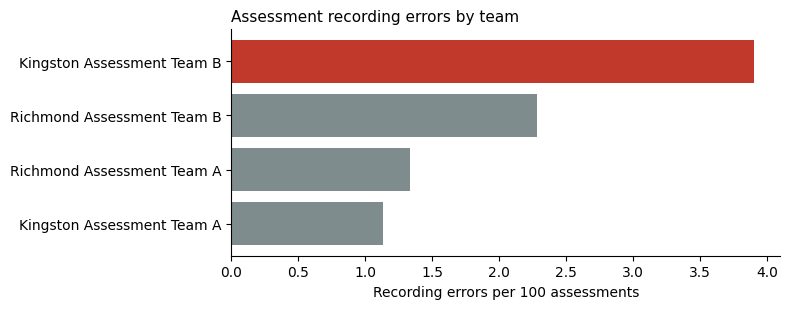

In [ ]:
asmt_err = exceptions[exceptions["source_table"] == "assessments"]
by_team = (asmt_err.groupby("team").size().rename("errors").to_frame()
           .join(assessments.groupby("team").size().rename("assessments")))
by_team["errors_per_100"] = (by_team["errors"] / by_team["assessments"] * 100).round(2)
by_team = by_team.sort_values("errors_per_100", ascending=False)
display(by_team)

by_worker = (asmt_err.dropna(subset=["worker_id"]).groupby(["worker_id", "team"]).size()
             .rename("errors").reset_index().sort_values("errors", ascending=False).head(5))
print("\nWorkers with the most assessment recording errors:")
display(by_worker)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(by_team.index, by_team["errors_per_100"], color=["#c0392b"] + ["#7f8c8d"] * (len(by_team) - 1))
ax.invert_yaxis(); ax.set_xlabel("Recording errors per 100 assessments")
ax.set_title("Assessment recording errors by team", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "charts/dq_by_team.png", dpi=150); plt.show()

### Clean the data before reporting

Performance figures must not be built on broken records. Before calculating KPIs:

* assessments failing **DQ02** (impossible dates) are excluded from timeliness,
* exact duplicate referrals (**DQ10**) are removed.

In real life, you would send the exceptions report to team managers, they would fix the records at source, and the next extract would be clean. Excluding records here is the reporting-side safety net.

In [ ]:
bad_asmt = set(exceptions.loc[exceptions["rule_id"] == "DQ02", "record_id"])
dup_refs = set(exceptions.loc[exceptions["rule_id"] == "DQ10", "record_id"])

assessments_clean = assessments[~assessments["assessment_id"].isin(bad_asmt)].copy()
referrals_clean   = referrals[~referrals["referral_id"].isin(dup_refs)].copy()

print(f"Assessments excluded: {len(bad_asmt)}  |  Duplicate referrals removed: {len(dup_refs)}")

Assessments excluded: 45  |  Duplicate referrals removed: 25


## 5. Build the SSDA903-style return

The SSDA903 return covers **every child looked after at any point in the year**. It's submitted as several linked tables. We build the three main ones:

| Table | One row per | Main fields |
|---|---|---|
| **Header** | child | CHILD, SEX, DOB, ETHNIC, UPN |
| **Episodes** | episode in the year | CHILD, DECOM, RNE, LS, CIN, PLACE, PLACE_PROVIDER, DEC, REC |
| **OC3** | care leaver aged 19–21 | CHILD, DOB, IN_TOUCH, ACTIV, ACCOM |

Dates use the DfE's `dd/mm/yyyy` format. Children whose errors would block submission are flagged, not silently dropped, so they can be fixed before the deadline.

In [ ]:
def fmt(d):
    return pd.to_datetime(d).dt.strftime("%d/%m/%Y")

# Episodes that overlap the reporting year
ep_year = episodes[(episodes["DECOM"] <= YEAR_END) & (episodes["DEC"].isna() | (episodes["DEC"] >= YEAR_START))].copy()
cla_in_year = ep_year["child_id"].unique()

header = children[children["child_id"].isin(cla_in_year)][["child_id", "sex", "dob", "ethnicity", "upn"]].copy()
header.columns = ["CHILD", "SEX", "DOB", "ETHNIC", "UPN"]
header["DOB"] = fmt(header["DOB"])
# Real returns use a code when a UPN is legitimately not held (e.g. children under 5)
header["UPN"] = header["UPN"].fillna("UN1")

ssda_episodes = ep_year[["child_id", "DECOM", "RNE", "LS", "CIN", "PLACE", "PLACE_PROVIDER", "DEC", "REC"]].copy()
ssda_episodes = ssda_episodes.rename(columns={"child_id": "CHILD"})
ssda_episodes["DECOM"] = fmt(ssda_episodes["DECOM"])
ssda_episodes["DEC"]   = fmt(ssda_episodes["DEC"])

oc3 = care_leavers[["child_id", "dob", "IN_TOUCH", "ACTIV", "ACCOM"]].rename(columns={"child_id": "CHILD", "dob": "DOB"})
oc3["DOB"] = fmt(oc3["DOB"])

# Flag children with blocking errors so they can be fixed before submission
blocking = set(exceptions.loc[(exceptions["severity"] == "Error") &
                              exceptions["source_table"].isin(["cla_episodes", "care_leavers", "children"]), "child_id"])
header["HAS_BLOCKING_ERROR"] = header["CHILD"].isin(blocking)

header.to_csv(OUT / "ssda903/header.csv", index=False)
ssda_episodes.to_csv(OUT / "ssda903/episodes.csv", index=False)
oc3.to_csv(OUT / "ssda903/oc3.csv", index=False)

print(f"Header:   {len(header):>5} children  ({header['HAS_BLOCKING_ERROR'].sum()} need fixing before submission)")
print(f"Episodes: {len(ssda_episodes):>5} rows")
print(f"OC3:      {len(oc3):>5} care leavers")
ssda_episodes.head(8)

Header:     190 children  (25 need fixing before submission)
Episodes:   320 rows
OC3:        115 care leavers


,CHILD,DECOM,RNE,LS,CIN,PLACE,PLACE_PROVIDER,DEC,REC
0,C100019,15/06/2025,S,C1,N1,U6,PR1,13/08/2025,X1
1,C100019,13/08/2025,P,C1,N1,U6,PR1,15/02/2026,X1
2,C100019,15/02/2026,L,C2,N1,U6,PR1,NaN,NaN
4,C100038,06/03/2025,L,C2,N1,K2,PR4,NaN,NaN
8,C100262,17/11/2024,S,C1,N5,U6,PR1,04/04/2025,X1
9,C100262,04/04/2025,P,C1,N5,U6,PR1,18/06/2025,X1
10,C100262,18/06/2025,L,C2,N5,U6,PR1,NaN,NaN
12,C100294,22/03/2025,P,V2,N1,U6,PR1,20/06/2025,E4A


## 6. Performance scorecard

Eight measures that appear in almost every children's social care performance framework. Each has a target and a **RAG** (red/amber/green) rating.

**About the targets:** they are *illustrative*, loosely informed by recent England averages. Before quoting any national comparison, always check the latest DfE publication.

| KPI | What it tells a manager | Better if |
|---|---|---|
| Assessments within 45 working days | Are children's needs understood quickly? | Higher |
| Re-referrals within 12 months | Did the first intervention work? | Lower |
| CP plans lasting 2+ years (of plans ended) | Is there drift in child protection? | Lower |
| Repeat CP plans (of plans started) | Are risks returning after plans end? | Lower |
| Children in care with 3+ placements in the year | Short-term placement stability | Lower |
| Long-term placement stability | Under-16s in care 2.5+ years, in the same placement for 2+ years | Higher |
| Care leavers (19–21) in education, employment or training | Outcomes after care | Higher |
| Care leavers in suitable accommodation | Outcomes after care | Higher |

In [ ]:
in_year = lambda s: s.between(YEAR_START, YEAR_END)

# ---- Flag columns: calculated once, reused for KPIs AND exported for Power BI ----
# Assessments
a = assessments_clean.copy()
a["working_days"]      = working_days_between(a["start_date"], a["end_date"])
a["completed_in_year"] = in_year(a["end_date"])
a["within_45_days"]    = (a["working_days"] <= 45)

# Referrals: was there a previous referral for the same child in the 12 months before?
r = referrals_clean.sort_values(["child_id", "referral_date"]).copy()
r["prev_referral"]   = r.groupby("child_id")["referral_date"].shift()
r["in_year"]         = in_year(r["referral_date"])
r["rereferral_12m"]  = (r["referral_date"] - r["prev_referral"]).dt.days <= 365

# CP plans: is this a second or later plan? How long did it last?
c = cp_plans.sort_values(["child_id", "start_date"]).copy()
c["plan_number"]     = c.groupby("child_id").cumcount() + 1
c["started_in_year"] = in_year(c["start_date"])
c["ended_in_year"]   = in_year(c["end_date"])
c["repeat_plan"]     = c["plan_number"] > 1
c["lasted_2yrs"]     = (c["end_date"] - c["start_date"]).dt.days >= 730

# Children in care on 31 March: placements during the year and long-term stability
e = episodes.copy()
e["LS_valid"] = e["LS"]
ov = e[(e["DECOM"] <= YEAR_END) & (e["DEC"].isna() | (e["DEC"] >= YEAR_START))]
new_placements = ov[ov["RNE"].isin(["S", "P"]) & in_year(ov["DECOM"])].groupby("child_id").size()
carried_in = ov[ov["DECOM"] < YEAR_START].groupby("child_id").size().clip(upper=1)
placements_in_year = new_placements.add(carried_in, fill_value=0)

snap = ov[ov["DEC"].isna() | (ov["DEC"] > YEAR_END)].drop_duplicates("child_id", keep="last").copy()
period_start = e[e["RNE"] == "S"].groupby("child_id")["DECOM"].max()
placement_start = e[e["RNE"].isin(["S", "P"])].groupby("child_id")["DECOM"].max()
snap = snap.merge(children[["child_id", "dob"]], on="child_id")
snap["age_31_march"]      = age_on(snap["dob"], YEAR_END)
snap["placements_in_year"] = snap["child_id"].map(placements_in_year).fillna(1).astype(int)
snap["three_plus"]        = snap["placements_in_year"] >= 3
snap["in_care_years"]     = (YEAR_END - snap["child_id"].map(period_start)).dt.days / 365.25
snap["placement_years"]   = (YEAR_END - snap["child_id"].map(placement_start)).dt.days / 365.25
snap["lt_cohort"]         = (snap["age_31_march"] < 16) & (snap["in_care_years"] >= 2.5)
snap["lt_stable"]         = snap["lt_cohort"] & (snap["placement_years"] >= 2)

# Care leavers
cl_df = care_leavers.copy()
cl_df["eet"]      = cl_df["ACTIV"].fillna("").str.startswith("F")
cl_df["suitable"] = cl_df["ACCOM"].fillna("").str.endswith("1")

print("Flag columns created.")

Flag columns created.


In [ ]:
KPI_DEF = [
  # key,            label,                                          target, higher_is_better
  ("assess_45",     "Assessments completed within 45 working days",  85, True),
  ("rereferral",    "Re-referrals within 12 months",                 20, False),
  ("cp_2yrs",       "CP plans ended that lasted 2+ years",            4, False),
  ("repeat_cp",     "CP plans that were a repeat plan",              22, False),
  ("cla_3plus",     "Children in care with 3+ placements in year",   10, False),
  ("lt_stability",  "Long-term placement stability",                 70, True),
  ("cl_eet",        "Care leavers (19-21) in education/employment/training", 55, True),
  ("cl_accom",      "Care leavers in suitable accommodation",        88, True),
]

def pct(num, den):
    return round(100 * num / den, 1) if den else np.nan

def kpis_for(boro=None):
    f = (lambda d: d) if boro is None else (lambda d: d[d["borough"] == boro])
    A, R, C, S, L = f(a), f(r), f(c), f(snap), f(cl_df)
    A_y = A[A["completed_in_year"]]; R_y = R[R["in_year"]]
    C_end = C[C["ended_in_year"]]; C_st = C[C["started_in_year"]]
    L_t = L[L["IN_TOUCH"] == "YES"]
    return {
        "assess_45":    (pct(A_y["within_45_days"].sum(), len(A_y)), len(A_y)),
        "rereferral":   (pct(R_y["rereferral_12m"].sum(), len(R_y)), len(R_y)),
        "cp_2yrs":      (pct(C_end["lasted_2yrs"].sum(), len(C_end)), len(C_end)),
        "repeat_cp":    (pct(C_st["repeat_plan"].sum(), len(C_st)), len(C_st)),
        "cla_3plus":    (pct(S["three_plus"].sum(), len(S)), len(S)),
        "lt_stability": (pct(S["lt_stable"].sum(), S["lt_cohort"].sum()), int(S["lt_cohort"].sum())),
        "cl_eet":       (pct(L["eet"].sum(), len(L)), len(L)),
        "cl_accom":     (pct(L["suitable"].sum(), len(L)), len(L)),
    }

def rag(value, target, higher):
    '''Green = target met; Amber = within 5 percentage points; Red = further away.'''
    if pd.isna(value): return "Grey"
    gap = (value - target) if higher else (target - value)
    return "Green" if gap >= 0 else ("Amber" if gap >= -5 else "Red")

rows = []
for area in ["All"] + BOROUGHS:
    res = kpis_for(None if area == "All" else area)
    for key, label, target, higher in KPI_DEF:
        val, n = res[key]
        rows.append({"area": area, "kpi_key": key, "kpi": label, "value_pct": val, "denominator": n,
                     "target_pct": target, "higher_is_better": higher, "rag": rag(val, target, higher)})
scorecard = pd.DataFrame(rows)

# Display as a wide table, coloured by RAG
wide = scorecard.pivot(index="kpi", columns="area", values="value_pct")[["All"] + BOROUGHS]
wide["Target"] = scorecard.drop_duplicates("kpi").set_index("kpi")["target_pct"]
wide = wide.loc[[k[1] for k in KPI_DEF]]
rag_lookup = scorecard.set_index(["kpi", "area"])["rag"]
COLOURS = {"Green": "#d5f5e3", "Amber": "#fdebd0", "Red": "#fadbd8", "Grey": "#eeeeee"}

def colour(col):
    if col.name == "Target":
        return [""] * len(col)
    return [f"background-color: {COLOURS[rag_lookup[(k, col.name)]]}" for k in col.index]

wide.style.apply(colour).format("{:.1f}%")

area,All,Kingston,Richmond,Target
kpi,,,,
Assessments completed within 45 working days,81.8%,77.5%,85.6%,85.0%
Re-referrals within 12 months,16.6%,16.0%,17.2%,20.0%
CP plans ended that lasted 2+ years,2.2%,4.6%,0.0%,4.0%
CP plans that were a repeat plan,23.8%,24.4%,23.1%,22.0%
Children in care with 3+ placements in year,12.6%,14.3%,10.9%,10.0%
Long-term placement stability,76.7%,72.0%,83.3%,70.0%
Care leavers (19-21) in education/employment/training,54.8%,50.0%,58.0%,55.0%
Care leavers in suitable accommodation,87.0%,82.6%,89.9%,88.0%


### Adding context: referral rate per 10,000 children

Raw counts can't be compared between boroughs of different sizes, so analysts use **rates per 10,000 children**.

In [ ]:
ref_year = r[r["in_year"]]
rates = ref_year.groupby("borough").size().rename("referrals").to_frame()
rates["population_0_17"] = rates.index.map(POP_UNDER_18)
rates["rate_per_10k"] = (rates["referrals"] / rates["population_0_17"] * 10_000).round(1)
rates

,referrals,population_0_17,rate_per_10k
borough,,,
Kingston,1091,40000,272.8
Richmond,1222,45000,271.6


## 7. Trends and breakdowns

A single year-end figure hides a lot. A monthly view shows *when* things slipped, and a team view shows *where*.

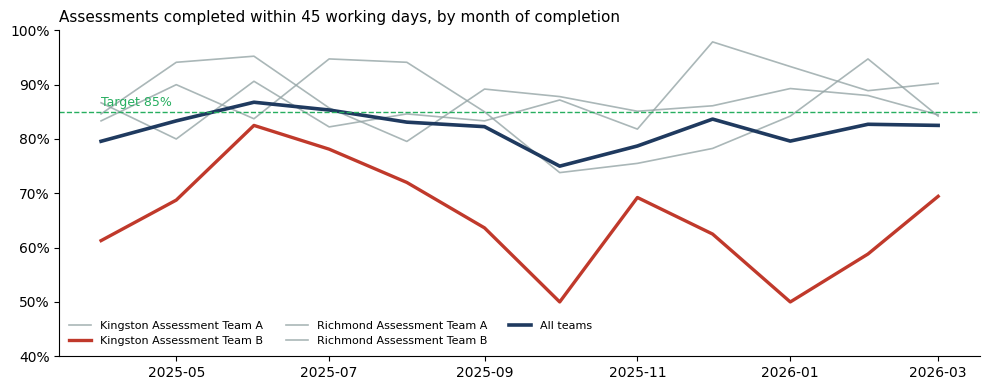

,% within 45 days,assessments completed
team,,
Kingston Assessment Team A,87.2,429
Kingston Assessment Team B,66.0,362
Richmond Assessment Team A,86.8,432
Richmond Assessment Team B,84.5,478


In [ ]:
a_y = a[a["completed_in_year"]].copy()
a_y["month"] = a_y["end_date"].dt.to_period("M").dt.to_timestamp()

monthly_team = (a_y.groupby(["month", "team"])["within_45_days"].mean() * 100).unstack()
monthly_all  = a_y.groupby("month")["within_45_days"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
for t in monthly_team.columns:
    is_focus = t == "Kingston Assessment Team B"
    ax.plot(monthly_team.index, monthly_team[t], lw=2.4 if is_focus else 1.2,
            color="#c0392b" if is_focus else "#95a5a6", label=t, alpha=1 if is_focus else 0.8)
ax.plot(monthly_all.index, monthly_all, color="#1f3a5f", lw=2.6, label="All teams")
ax.axhline(85, ls="--", color="#27ae60", lw=1); ax.text(monthly_all.index[0], 86, "Target 85%", color="#27ae60", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(40, 100)
ax.set_title("Assessments completed within 45 working days, by month of completion", loc="left", fontsize=11)
ax.legend(fontsize=8, ncol=3, frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "charts/assessment_timeliness.png", dpi=150); plt.show()

team_year = (a_y.groupby("team")["within_45_days"].agg(["mean", "size"]))
team_year["mean"] = (team_year["mean"] * 100).round(1)
team_year.columns = ["% within 45 days", "assessments completed"]
team_year

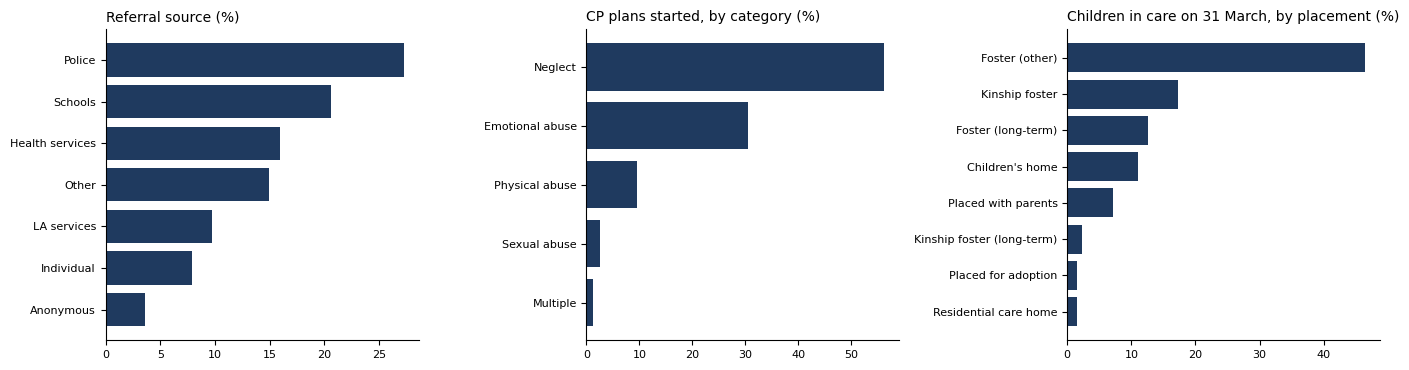

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

src = ref_year["source"].value_counts(normalize=True).sort_values() * 100
axes[0].barh(src.index, src.values, color="#1f3a5f"); axes[0].set_title("Referral source (%)", loc="left", fontsize=10)

cat = c[c["started_in_year"]]["category"].value_counts(normalize=True).sort_values() * 100
axes[1].barh(cat.index, cat.values, color="#1f3a5f"); axes[1].set_title("CP plans started, by category (%)", loc="left", fontsize=10)

PLACE_NAMES = {"U1": "Kinship foster (long-term)", "U3": "Kinship foster", "U4": "Foster (long-term)",
               "U6": "Foster (other)", "K2": "Children's home", "R1": "Residential care home",
               "P1": "Placed with parents", "A6": "Placed for adoption"}
plc = snap["PLACE"].map(PLACE_NAMES).value_counts(normalize=True).sort_values() * 100
axes[2].barh(plc.index, plc.values, color="#1f3a5f"); axes[2].set_title("Children in care on 31 March, by placement (%)", loc="left", fontsize=10)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.savefig(OUT / "charts/service_mix.png", dpi=150); plt.show()

## 8. Export for Power BI and the web dashboard

Power BI works best with a **star schema**: fact tables (events) linked to dimension tables (descriptions) through shared keys. The flag columns calculated above are exported as 1/0, which keeps every DAX measure a simple `DIVIDE(SUM(flag), COUNTROWS(table))`.

In [ ]:
def yesno(df, cols):
    d = df.copy()
    for col in cols:
        d[col] = d[col].fillna(False).astype(int)
    return d

pb = OUT / "powerbi"

dim_child = children[["child_id", "borough", "sex", "dob", "ethnicity", "disability"]].copy()
dim_child["sex"] = dim_child["sex"].map({1: "Male", 2: "Female"})
dim_child.to_csv(pb / "dim_child.csv", index=False)
workers.to_csv(pb / "dim_worker.csv", index=False)

yesno(r[["referral_id", "child_id", "borough", "team", "referral_date", "source", "outcome", "in_year", "rereferral_12m"]],
      ["in_year", "rereferral_12m"]).to_csv(pb / "fact_referrals.csv", index=False)

# Export ALL assessments (so error rates use the full count), with a flag for the ones
# excluded from KPIs. Excluded rows get 0 in every KPI flag, so the measures ignore them.
fa = assessments.merge(a[["assessment_id", "working_days", "completed_in_year", "within_45_days"]],
                       on="assessment_id", how="left")
fa["kpi_excluded"] = fa["assessment_id"].isin(bad_asmt)
yesno(fa[["assessment_id", "referral_id", "child_id", "borough", "team", "worker_id", "start_date", "end_date",
          "assessment_outcome", "working_days", "completed_in_year", "within_45_days", "kpi_excluded"]],
      ["completed_in_year", "within_45_days", "kpi_excluded"]).to_csv(pb / "fact_assessments.csv", index=False)

yesno(c[["cp_plan_id", "child_id", "borough", "category", "start_date", "end_date", "plan_number",
         "started_in_year", "ended_in_year", "repeat_plan", "lasted_2yrs"]],
      ["started_in_year", "ended_in_year", "repeat_plan", "lasted_2yrs"]).to_csv(pb / "fact_cp_plans.csv", index=False)

episodes.to_csv(pb / "fact_cla_episodes.csv", index=False)

snap_out = snap[["child_id", "borough", "LS", "PLACE", "PLACE_PROVIDER", "age_31_march", "placements_in_year",
                 "three_plus", "lt_cohort", "lt_stable"]].copy()
snap_out["placement_name"] = snap_out["PLACE"].map(PLACE_NAMES)
yesno(snap_out, ["three_plus", "lt_cohort", "lt_stable"]).to_csv(pb / "fact_cla_snapshot.csv", index=False)

yesno(cl_df[["child_id", "borough", "IN_TOUCH", "ACTIV", "ACCOM", "eet", "suitable"]],
      ["eet", "suitable"]).to_csv(pb / "fact_care_leavers.csv", index=False)

exceptions.to_csv(pb / "dq_exceptions.csv", index=False)
scorecard.to_csv(pb / "kpi_scorecard.csv", index=False)

pd.DataFrame(KPI_DEF, columns=["kpi_key", "kpi", "target_pct", "higher_is_better"]).to_csv(pb / "kpi_targets.csv", index=False)

print("Power BI files:")
for f in sorted(pb.glob("*.csv")):
    print(f"  {f.name:<26} {sum(1 for _ in open(f)) - 1:>6,} rows")

/tmp/ipykernel_927/986976807.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d[col] = d[col].fillna(False).astype(int)
/tmp/ipykernel_927/986976807.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d[col] = d[col].fillna(False).astype(int)


Power BI files:
  dim_child.csv               5,505 rows
  dim_worker.csv                 32 rows
  dq_exceptions.csv             372 rows
  fact_assessments.csv        4,900 rows
  fact_care_leavers.csv         115 rows
  fact_cla_episodes.csv         758 rows
  fact_cla_snapshot.csv         127 rows
  fact_cp_plans.csv             793 rows
  fact_referrals.csv          6,494 rows
  kpi_scorecard.csv              24 rows
  kpi_targets.csv                 8 rows


In [ ]:
# A compact JSON file that the GitHub Pages dashboard (index.html) reads
mt = monthly_team.round(1)
dash = {
    "generated": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "reporting_year": "2025-26",
    "headline": {
        "children": int(children["child_id"].nunique()),
        "referrals_in_year": int(len(ref_year)),
        "assessments_completed": int(len(a_y)),
        "cp_plans_open": int(c["end_date"].isna().sum()),
        "children_in_care": int(len(snap)),
        "care_leavers": int(len(cl_df)),
        "dq_exceptions": int(len(exceptions)),
        "dq_errors": int((exceptions["severity"] == "Error").sum()),
    },
    "scorecard": scorecard.replace({np.nan: None}).to_dict(orient="records"),
    "monthly": {
        "months": [m.strftime("%b %y") for m in mt.index],
        "all": monthly_all.round(1).tolist(),
        "teams": {t: mt[t].tolist() for t in mt.columns},
    },
    "referral_rates": rates.reset_index().to_dict(orient="records"),
    "referral_sources": src.round(1).sort_values(ascending=False).to_dict(),
    "cp_categories": cat.round(1).sort_values(ascending=False).to_dict(),
    "placements": plc.round(1).sort_values(ascending=False).to_dict(),
    "dq_by_rule": summary.to_dict(orient="records"),
    "dq_by_team": by_team.reset_index().to_dict(orient="records"),
    "team_timeliness": team_year.reset_index().rename(columns={"% within 45 days": "pct", "assessments completed": "n"}).to_dict(orient="records"),
}
with open(OUT / "dashboard/dashboard_data.json", "w") as f:
    json.dump(dash, f, indent=2, default=str)
print("Saved outputs/dashboard/dashboard_data.json")

Saved outputs/dashboard/dashboard_data.json


### Download everything (Colab)

This zips the `outputs` folder and downloads it, so you can load the CSVs into Power BI on your own machine.

In [ ]:
import shutil
shutil.make_archive("csc_pipeline_outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("csc_pipeline_outputs.zip")
except ImportError:
    print("Not running in Colab. The zip is saved next to this notebook: csc_pipeline_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. What the numbers say

The cell below prints the headline story automatically from the results, so the summary always matches the data.

In [ ]:
allk = scorecard[scorecard["area"] == "All"].set_index("kpi_key")
kb = team_year.loc["Kingston Assessment Team B"]
others = a_y[a_y["team"] != "Kingston Assessment Team B"]["within_45_days"].mean() * 100
worst_month = monthly_all.idxmin()

print("HEADLINES, 2025-26 (synthetic data)")
print("-" * 60)
print(f"- {allk.loc['assess_45','value_pct']}% of assessments were completed within 45 working days (target 85%, {allk.loc['assess_45','rag']}).")
print(f"- Kingston Assessment Team B completed {kb['% within 45 days']}% on time, against {others:.1f}% for the other three teams.")
late_in_worst = a_y[(a_y["month"] == worst_month) & ~a_y["within_45_days"]]
common_start = late_in_worst["start_date"].dt.strftime("%B").value_counts().index[0]
print(f"- Timeliness was lowest for assessments completed in {worst_month:%B %Y} ({monthly_all.min():.1f}%). "
      f"Most of the late ones started in {common_start}, when staff leave peaks.")
print(f"- Re-referral rate: {allk.loc['rereferral','value_pct']}% ({allk.loc['rereferral','rag']}). Repeat CP plans: {allk.loc['repeat_cp','value_pct']}% ({allk.loc['repeat_cp','rag']}).")
print(f"- {allk.loc['cla_3plus','value_pct']}% of children in care had 3+ placements in the year ({allk.loc['cla_3plus','rag']}).")
print(f"- Care leavers in EET: {allk.loc['cl_eet','value_pct']}%; in suitable accommodation: {allk.loc['cl_accom','value_pct']}%.")
print(f"- {len(exceptions)} data quality exceptions found; {int((exceptions['severity']=='Error').sum())} are errors that would block the SSDA903 return.")
print(f"- Every planted error was caught: {'Yes' if (check['all_caught']=='Yes').all() else 'No'}.")

HEADLINES, 2025-26 (synthetic data)
------------------------------------------------------------
- 81.8% of assessments were completed within 45 working days (target 85%, Amber).
- Kingston Assessment Team B completed 66.0% on time, against 86.1% for the other three teams.
- Timeliness was lowest for assessments completed in October 2025 (75.0%). Most of the late ones started in July, when staff leave peaks.
- Re-referral rate: 16.6% (Green). Repeat CP plans: 23.8% (Amber).
- 12.6% of children in care had 3+ placements in the year (Amber).
- Care leavers in EET: 54.8%; in suitable accommodation: 87.0%.
- 372 data quality exceptions found; 168 are errors that would block the SSDA903 return.
- Every planted error was caught: Yes.


### Limitations, honestly

* The data is synthetic. The patterns are ones I built in, so this project demonstrates **method**, not real findings about any borough.
* DfE code lists and validation rules are simplified. The real SSDA903 guide runs to over 100 pages, with many more edge cases.
* Targets are illustrative. Real benchmarking would use published DfE figures and statistical neighbours.
* Timeliness is measured from assessment start. Statutory guidance counts from the point of referral, and local definitions vary.

### Next steps

* Add a Children in Need census module (CIN plans and factors identified at assessment).
* Schedule the validation rules to run weekly and email each team its own exceptions.
* Replace the illustrative targets with published DfE statistical-neighbour averages.